# When Outliers Matter: Investigating Gradient-Based Data Selection Under Spurious Correlations

**UCLA CS 260D — Final Project | Fall 2026**

## 3. Experiment 2: EPIC-Inspired Gradient-Based Data Selection

### 3.1 Objective

Investigate whether gradient-space isolation disproportionately identifies minority examples in CelebA and how removing these examples affects worst-group accuracy.

We use the pretrained ResNet-18 features and ERM checkpoint from Experiment 1. Per-example classification gradients will be analyzed to identify isolated training samples.

We compare group-specific retention rates and model performance before and after filtering. Group annotations are used only for evaluation, not for determining which examples to remove.

### 3.2 Experimental Configuration

- **Dataset:** CelebA (162,770 training examples)
- **Target:** `Blond_Hair`
- **Spurious attribute:** `Male`
- **Architecture:** Frozen ResNet-18 + linear classifier
- **Reference model:** Best ERM checkpoint
- **Selection method:** EPIC-inspired gradient-space isolation
- **Evaluation:** Average accuracy, worst-group accuracy, and group retention rates
- **Random seed:** 42

All methods use the same cached features and official dataset partitions.

In [1]:

# ============================================================
# 3.3 Load ERM checkpoint and cached CelebA features
# ============================================================

import random
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import pandas as pd

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

# ------------------------------------------------------------
# 1. Define project paths
# ------------------------------------------------------------

FEATURE_DIR = Path("data/processed/features")
CHECKPOINT_PATH = Path("results/models/erm_celeba.pt")

assert FEATURE_DIR.is_dir(), "Feature cache not found."
assert CHECKPOINT_PATH.is_file(), "ERM checkpoint not found."

# ------------------------------------------------------------
# 2. Load cached training features
# ------------------------------------------------------------

X_train = np.load(
    FEATURE_DIR / "train_features.npy",
    mmap_mode="r"
)

y_train = np.load(
    FEATURE_DIR / "train_labels.npy"
)

groups_train = np.load(
    FEATURE_DIR / "train_groups.npy"
)

# ------------------------------------------------------------
# 3. Restore the trained ERM classifier
# ------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

erm_model = nn.Linear(
    checkpoint["input_dim"],
    checkpoint["num_classes"]
).to(device)

erm_model.load_state_dict(
    checkpoint["model_state_dict"]
)

erm_model.eval()

# ------------------------------------------------------------
# 4. Verify data and model
# ------------------------------------------------------------

assert X_train.shape == (162770, 512)
assert y_train.shape == (162770,)
assert groups_train.shape == (162770,)

assert np.isin(y_train, [0, 1]).all()
assert np.isin(groups_train, [0, 1, 2, 3]).all()

print("=" * 55)
print("EPIC — Experiment Initialization")
print("=" * 55)

print(f"Device: {device}")
print(f"Training examples: {len(X_train):,}")
print(f"Feature dimensions: {X_train.shape[1]}")
print(f"ERM checkpoint epoch: {checkpoint['best_epoch']}")

print("\nTraining group distribution:")
for group_id in range(4):
    count = int(np.sum(groups_train == group_id))
    print(f"Group {group_id}: {count:,}")

print("\nEPIC experiment initialized successfully!")


EPIC — Experiment Initialization
Device: mps
Training examples: 162,770
Feature dimensions: 512
ERM checkpoint epoch: 19

Training group distribution:
Group 0: 71,629
Group 1: 66,874
Group 2: 22,880
Group 3: 1,387

EPIC experiment initialized successfully!


### 3.3 Per-Example Gradient Computation

Compute cross-entropy gradients with respect to the trained ERM classification head for all training examples.

Each example is represented by a 1,026-dimensional gradient vector (weights and biases). These vectors will be used to analyze gradient-space isolation and identify candidates for filtering.

In [2]:

# ============================================================
# 3.3 Compute per-example classification gradients
# ============================================================

from numpy.lib.format import open_memmap
import time
import os

GRADIENT_DIR = Path("data/processed/gradients")
GRADIENT_DIR.mkdir(parents=True, exist_ok=True)

GRADIENT_DIM = 1026
BATCH_SIZE = 1024

gradient_path = GRADIENT_DIR / "erm_gradients.npy"
temp_path = GRADIENT_DIR / "erm_gradients.tmp.npy"

n_samples = len(X_train)

# Disk-backed storage avoids keeping all gradients in RAM.
gradients = open_memmap(
    temp_path,
    mode="w+",
    dtype=np.float32,
    shape=(n_samples, GRADIENT_DIM),
)

erm_model.eval()
start_time = time.perf_counter()

with torch.inference_mode():

    for start in range(0, n_samples, BATCH_SIZE):

        end = min(start + BATCH_SIZE, n_samples)

        # Cached ResNet-18 features
        features = torch.as_tensor(
            np.asarray(X_train[start:end]).copy(),
            dtype=torch.float32,
            device=device,
        )

        labels = torch.as_tensor(
            y_train[start:end],
            dtype=torch.long,
            device=device,
        )

        # Forward pass
        logits = erm_model(features)
        probabilities = torch.softmax(logits, dim=1)

        # dL/dlogits = probabilities - one_hot(labels)
        errors = probabilities.clone()
        errors[
            torch.arange(len(labels), device=device),
            labels
        ] -= 1.0

        # Per-example weight gradients: [B, 2, 512]
        weight_grads = (
            errors.unsqueeze(2) * features.unsqueeze(1)
        )

        # Concatenate weight and bias gradients: [B, 1026]
        batch_gradients = torch.cat(
            [
                weight_grads.reshape(len(labels), -1),
                errors,
            ],
            dim=1,
        )

        gradients[start:end] = (
            batch_gradients.cpu().numpy()
        )

        if end % (BATCH_SIZE * 25) == 0 or end == n_samples:
            print(
                f"Processed {end:,}/{n_samples:,} "
                f"({end / n_samples:.1%})"
            )

# Save completed gradient cache.
gradients.flush()
del gradients

os.replace(temp_path, gradient_path)

elapsed = time.perf_counter() - start_time

# Verify gradient cache
gradient_cache = np.load(
    gradient_path,
    mmap_mode="r"
)

assert gradient_cache.shape == (n_samples, GRADIENT_DIM)

print("\n" + "=" * 55)
print("Per-Example Gradient Extraction")
print("=" * 55)

print(f"Samples: {n_samples:,}")
print(f"Gradient dimension: {GRADIENT_DIM}")
print(f"Shape: {gradient_cache.shape}")
print(f"Extraction time: {elapsed:.1f} seconds")
print(f"Saved to: {gradient_path}")

print("\nGradient extraction completed successfully!")


Processed 25,600/162,770 (15.7%)
Processed 51,200/162,770 (31.5%)
Processed 76,800/162,770 (47.2%)
Processed 102,400/162,770 (62.9%)
Processed 128,000/162,770 (78.6%)
Processed 153,600/162,770 (94.4%)
Processed 162,770/162,770 (100.0%)

Per-Example Gradient Extraction
Samples: 162,770
Gradient dimension: 1026
Shape: (162770, 1026)
Extraction time: 1.6 seconds
Saved to: data/processed/gradients/erm_gradients.npy

Gradient extraction completed successfully!


### 3.4 Gradient Magnitude Analysis

Compare per-example gradient norms across the four CelebA groups. Examine whether minority examples have larger gradients, while distinguishing gradient magnitude from gradient-space isolation.

CelebA — Per-Example Gradient Magnitude
 Group  Samples  Mean Norm  Median Norm  90th Percentile
     0    71629     2.2366       0.2375           7.0423
     1    66874     0.6601       0.1243           1.4648
     2    22880     8.1041       4.7995          21.7458
     3     1387    21.0137      22.5564          30.6154


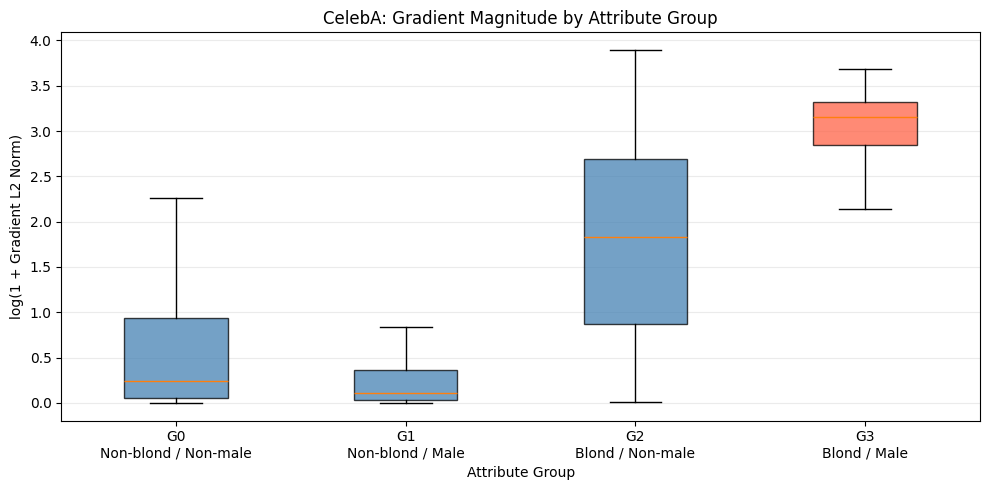


Gradient magnitude analysis saved successfully!


In [3]:

# ============================================================
# 3.4 Gradient magnitude analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Calculate per-example gradient L2 norms
# ------------------------------------------------------------

gradient_cache = np.load(
    GRADIENT_DIR / "erm_gradients.npy",
    mmap_mode="r"
)

gradient_norms = np.empty(len(y_train), dtype=np.float32)

BATCH_SIZE = 4096

for start in range(0, len(y_train), BATCH_SIZE):
    end = min(start + BATCH_SIZE, len(y_train))

    batch = np.asarray(gradient_cache[start:end])

    gradient_norms[start:end] = np.linalg.norm(
        batch,
        axis=1
    )

assert np.isfinite(gradient_norms).all()

# ------------------------------------------------------------
# 2. Compare gradient norms across groups
# ------------------------------------------------------------

group_names = {
    0: "Non-blond / Non-male",
    1: "Non-blond / Male",
    2: "Blond / Non-male",
    3: "Blond / Male",
}

summary = []

for group_id in range(4):
    values = gradient_norms[groups_train == group_id]

    summary.append({
        "Group": group_id,
        "Samples": len(values),
        "Mean Norm": values.mean(),
        "Median Norm": np.median(values),
        "90th Percentile": np.percentile(values, 90),
    })

summary_df = pd.DataFrame(summary)

print("=" * 65)
print("CelebA — Per-Example Gradient Magnitude")
print("=" * 65)

print(summary_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

# ------------------------------------------------------------
# 3. Visualize gradient norm distributions
# ------------------------------------------------------------

rng = np.random.default_rng(SEED)
plot_data = []

for group_id in range(4):
    values = gradient_norms[groups_train == group_id]

    # Sample for visualization only.
    sample_size = min(2000, len(values))

    sampled = rng.choice(
        values,
        size=sample_size,
        replace=False
    )

    plot_data.append(np.log1p(sampled))

fig, ax = plt.subplots(figsize=(10, 5))

bp = ax.boxplot(
    plot_data,
    tick_labels=[
        f"G{i}\n{group_names[i]}"
        for i in range(4)
    ],
    showfliers=False,
    patch_artist=True
)

for i, box in enumerate(bp["boxes"]):
    box.set_facecolor(
        "tomato" if i == 3 else "steelblue"
    )
    box.set_alpha(0.75)

ax.set_title("CelebA: Gradient Magnitude by Attribute Group")
ax.set_ylabel("log(1 + Gradient L2 Norm)")
ax.set_xlabel("Attribute Group")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

# ------------------------------------------------------------
# 4. Save results
# ------------------------------------------------------------

FIGURE_DIR = Path("results/figures")
METRICS_DIR = Path("results/metrics")

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURE_DIR / "epic_gradient_magnitudes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

summary_df.to_csv(
    METRICS_DIR / "epic_gradient_magnitude_summary.csv",
    index=False
)

np.save(
    GRADIENT_DIR / "erm_gradient_norms.npy",
    gradient_norms
)

print("\nGradient magnitude analysis saved successfully!")


### 3.5 Gradient-Space Isolation Analysis

Measure gradient-direction isolation using cosine similarity to a fixed random reference set.

For each example, compute the mean similarity to its five nearest reference gradients. Lower similarity indicates greater estimated isolation. Compare isolation scores across groups, without using group labels during scoring.

Processed 25,600/162,770
Processed 51,200/162,770
Processed 76,800/162,770
Processed 102,400/162,770
Processed 128,000/162,770
Processed 153,600/162,770
Processed 162,770/162,770

Gradient-Space Isolation Summary
 Group  Samples  Mean Isolation  Median Isolation  90th Percentile
     0    71629          0.1083            0.1030           0.1554
     1    66874          0.1239            0.1194           0.1680
     2    22880          0.1069            0.0995           0.1536
     3     1387          0.1468            0.1439           0.1940


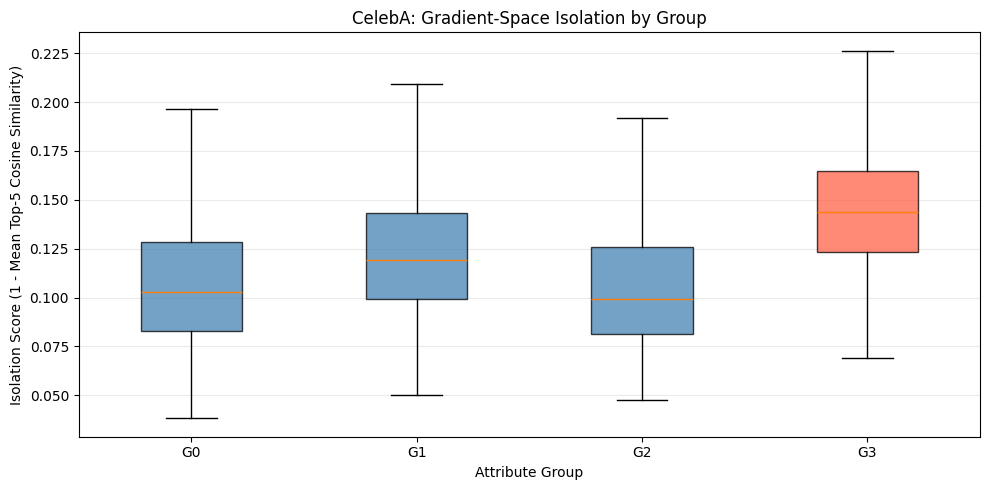


Gradient isolation analysis saved successfully!


In [4]:

# ============================================================
# 3.5 Gradient-space isolation using cosine similarity
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REFERENCE_SIZE = 2048
K_NEIGHBORS = 5
BATCH_SIZE = 256
EPS = 1e-12

rng = np.random.default_rng(SEED)
n_samples = len(y_train)

# ------------------------------------------------------------
# 1. Select a reproducible random reference set
# ------------------------------------------------------------

reference_indices = rng.choice(
    n_samples,
    size=REFERENCE_SIZE,
    replace=False
)

# Normalize gradients to compare directions, not magnitudes.
reference = torch.from_numpy(
    np.asarray(gradient_cache[reference_indices]).copy()
).to(device)

reference = torch.nn.functional.normalize(
    reference, p=2, dim=1, eps=EPS
)

# ------------------------------------------------------------
# 2. Compute nearest-reference cosine similarity
# ------------------------------------------------------------

similarity_scores = np.empty(n_samples, dtype=np.float32)

for start in range(0, n_samples, BATCH_SIZE):
    end = min(start + BATCH_SIZE, n_samples)

    batch = torch.from_numpy(
        np.asarray(gradient_cache[start:end]).copy()
    ).to(device)

    batch = torch.nn.functional.normalize(
        batch, p=2, dim=1, eps=EPS
    )

    # Cosine similarity: [batch_size, reference_size]
    similarities = batch @ reference.T

    # Exclude self-matches for examples in the reference set.
    self_matches = (
        np.arange(start, end)[:, None]
        == reference_indices[None, :]
    )

    rows, cols = np.where(self_matches)

    if len(rows):
        similarities[
            torch.as_tensor(rows, device=device),
            torch.as_tensor(cols, device=device)
        ] = -float("inf")

    nearest = torch.topk(
        similarities,
        k=K_NEIGHBORS,
        dim=1
    ).values

    similarity_scores[start:end] = (
        nearest.mean(dim=1).cpu().numpy()
    )

    if end % (BATCH_SIZE * 100) == 0 or end == n_samples:
        print(f"Processed {end:,}/{n_samples:,}")

# Higher isolation = less similar to nearby reference examples.
isolation_scores = 1.0 - similarity_scores

assert np.isfinite(isolation_scores).all()

# ------------------------------------------------------------
# 3. Analyze isolation by group (evaluation only)
# ------------------------------------------------------------

summary = []

for group_id in range(4):
    values = isolation_scores[groups_train == group_id]

    summary.append({
        "Group": group_id,
        "Samples": len(values),
        "Mean Isolation": values.mean(),
        "Median Isolation": np.median(values),
        "90th Percentile": np.percentile(values, 90)
    })

isolation_df = pd.DataFrame(summary)

print("\nGradient-Space Isolation Summary")
print("=" * 65)
print(isolation_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

# ------------------------------------------------------------
# 4. Visualize isolation distributions
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

plot_data = [
    isolation_scores[groups_train == group_id]
    for group_id in range(4)
]

bp = ax.boxplot(
    plot_data,
    tick_labels=["G0", "G1", "G2", "G3"],
    showfliers=False,
    patch_artist=True
)

for i, box in enumerate(bp["boxes"]):
    box.set_facecolor(
        "tomato" if i == 3 else "steelblue"
    )
    box.set_alpha(0.75)

ax.set_title("CelebA: Gradient-Space Isolation by Group")
ax.set_xlabel("Attribute Group")
ax.set_ylabel("Isolation Score (1 - Mean Top-5 Cosine Similarity)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "epic_gradient_isolation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Save scores and summary
# ------------------------------------------------------------

np.save(
    GRADIENT_DIR / "erm_isolation_scores.npy",
    isolation_scores
)

np.save(
    GRADIENT_DIR / "isolation_reference_indices.npy",
    reference_indices
)

isolation_df.to_csv(
    METRICS_DIR / "epic_gradient_isolation_summary.csv",
    index=False
)

print("\nGradient isolation analysis saved successfully!")


### 3.6 Gradient-Based Filtering and Minority Retention

Remove the highest-isolation training examples at 5%, 10%, and 20% filtering rates.

Measure group-specific removal rates, retention rates, and representation changes. Compare observed removal rates against proportional random filtering.

EPIC-Inspired Isolation Filtering — Group Retention
 Filter Rate (%)  Group  Original  Removed  Retained  Removal Rate (%)  Retention Rate (%)  Removal Enrichment
               5      0     71629     2728     68901              3.81               96.19                0.76
               5      1     66874     4307     62567              6.44               93.56                1.29
               5      2     22880      880     22000              3.85               96.15                0.77
               5      3      1387      223      1164             16.08               83.92                3.22
              10      0     71629     5604     66025              7.82               92.18                0.78
              10      1     66874     8617     58257             12.89               87.11                1.29
              10      2     22880     1669     21211              7.29               92.71                0.73
              10      3      1387      387      1000        

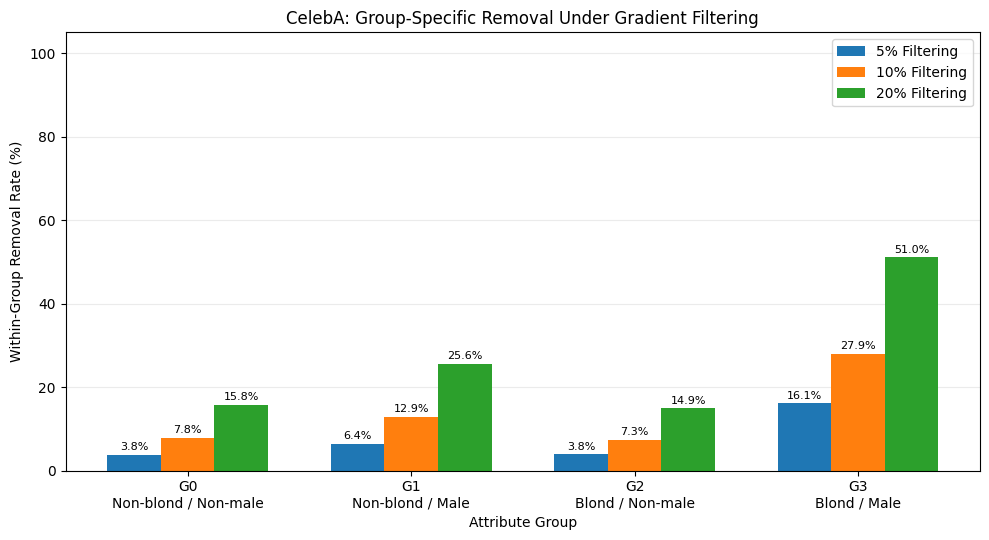


Figure saved to: results/figures/epic_group_removal_rates.png
Group retention analysis completed!


In [5]:

# ============================================================
# 3.6 Simulate isolation-based data filtering
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILTER_RATES = [0.05, 0.10, 0.20]
n_samples = len(isolation_scores)

# Descending isolation score; deterministic tie-breaking.
ranked_indices = np.lexsort((
    np.arange(n_samples),
    -isolation_scores
))

baseline_counts = np.bincount(groups_train, minlength=4)

records = []

for rate in FILTER_RATES:

    n_remove = round(rate * n_samples)
    removed_indices = ranked_indices[:n_remove]

    removed_mask = np.zeros(n_samples, dtype=bool)
    removed_mask[removed_indices] = True

    # Save selected indices for reproducibility.
    np.save(
        GRADIENT_DIR / f"removed_{int(rate*100)}pct.npy",
        removed_indices
    )

    for group_id in range(4):

        group_mask = groups_train == group_id
        original = int(baseline_counts[group_id])
        removed = int((removed_mask & group_mask).sum())
        retained = original - removed

        records.append({
            "Filter Rate (%)": int(rate * 100),
            "Group": group_id,
            "Original": original,
            "Removed": removed,
            "Retained": retained,
            "Removal Rate (%)": 100 * removed / original,
            "Retention Rate (%)": 100 * retained / original,
            "Removal Enrichment": (removed / original) / rate,
        })

retention_df = pd.DataFrame(records)

# ------------------------------------------------------------
# 2. Display group-specific removal and retention
# ------------------------------------------------------------

print("=" * 75)
print("EPIC-Inspired Isolation Filtering — Group Retention")
print("=" * 75)

print(retention_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.2f}"
))

# ------------------------------------------------------------
# 3. Visualize removal rates
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(4)
width = 0.24

for i, rate in enumerate(FILTER_RATES):

    subset = retention_df[
        retention_df["Filter Rate (%)"] == int(rate * 100)
    ].sort_values("Group")

    bars = ax.bar(
        x + (i - 1) * width,
        subset["Removal Rate (%)"],
        width,
        label=f"{int(rate * 100)}% Filtering"
    )

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=2,
        fontsize=8
    )

ax.set_xticks(x)
ax.set_xticklabels([
    "G0\nNon-blond / Non-male",
    "G1\nNon-blond / Male",
    "G2\nBlond / Non-male",
    "G3\nBlond / Male"
])

ax.set_ylabel("Within-Group Removal Rate (%)")
ax.set_xlabel("Attribute Group")
ax.set_title(
    "CelebA: Group-Specific Removal Under Gradient Filtering"
)
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# Room for labels if removal is extremely uneven.
ax.set_ylim(0, 105)

plt.tight_layout()

save_path = FIGURE_DIR / "epic_group_removal_rates.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 4. Save evaluation metrics
# ------------------------------------------------------------

retention_df.to_csv(
    METRICS_DIR / "epic_group_retention.csv",
    index=False
)

print(f"\nFigure saved to: {save_path}")
print("Group retention analysis completed!")


### 3.7 Model Retraining After Filtering

Retrain the linear classifier after removing 10% of training examples using gradient isolation or random selection.

Compare both methods against ERM using overall and worst-group validation accuracy. Select checkpoints using validation loss.

In [6]:

# ============================================================
# 3.7 Retrain classifiers with 10% data filtering
# ============================================================

import copy
import json
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader, TensorDataset

FILTER_RATE = 0.10
EPOCHS = 20
LR = 1e-3
WEIGHT_DECAY = 1e-4

n = len(y_train)
n_remove = round(FILTER_RATE * n)

# Reuse existing cached features and labels.
X = np.load(FEATURE_DIR / "train_features.npy", mmap_mode="r")
Y = np.load(FEATURE_DIR / "train_labels.npy")

Xv = torch.from_numpy(
    np.load(FEATURE_DIR / "val_features.npy").copy()
)
Yv = np.load(FEATURE_DIR / "val_labels.npy")
Gv = np.load(FEATURE_DIR / "val_groups.npy")

# ------------------------------------------------------------
# 1. Prepare filtering methods
# ------------------------------------------------------------

removed_epic = np.load(
    GRADIENT_DIR / "removed_10pct.npy"
)

rng = np.random.default_rng(SEED)
removed_random = rng.choice(n, n_remove, replace=False)

assert len(removed_epic) == n_remove
assert len(np.unique(removed_epic)) == n_remove
assert np.all((removed_epic >= 0) & (removed_epic < n))

all_indices = np.arange(n)

methods = {
    "isolation": np.setdiff1d(all_indices, removed_epic),
    "random": np.setdiff1d(all_indices, removed_random),
}

# ------------------------------------------------------------
# 2. Evaluation function
# ------------------------------------------------------------

def evaluate_model(model):
    model.eval()
    predictions = []

    with torch.inference_mode():
        for start in range(0, len(Xv), 1024):
            batch = Xv[start:start + 1024].to(device)
            logits = model(batch)
            predictions.append(
                logits.argmax(1).cpu().numpy()
            )

    predictions = np.concatenate(predictions)
    correct = predictions == Yv

    group_acc = {
        g: float(correct[Gv == g].mean() * 100)
        for g in range(4)
    }

    return {
        "overall": float(correct.mean() * 100),
        "worst_group": min(group_acc.values()),
        "group_accuracies": group_acc,
    }

# ------------------------------------------------------------
# 3. Train from scratch on retained features
# ------------------------------------------------------------

def train_filtered_model(indices, name):
    torch.manual_seed(SEED)

    model = torch.nn.Linear(512, 2).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY,
    )
    criterion = torch.nn.CrossEntropyLoss()

    dataset = TensorDataset(
        torch.from_numpy(np.asarray(X[indices]).copy()),
        torch.from_numpy(Y[indices]).long()
    )

    loader = DataLoader(
        dataset,
        batch_size=512,
        shuffle=True,
    )

    val_loader = DataLoader(
        TensorDataset(Xv, torch.from_numpy(Yv).long()),
        batch_size=1024,
        shuffle=False,
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    history = []

    for epoch in range(EPOCHS):
        model.train()
        train_sum = 0.0

        for features, labels in loader:
            features = features.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            loss = criterion(model(features), labels)
            loss.backward()
            optimizer.step()

            train_sum += loss.item() * len(labels)

        model.eval()
        val_sum = 0.0

        with torch.inference_mode():
            for features, labels in val_loader:
                features = features.to(device)
                labels = labels.to(device)

                loss = criterion(model(features), labels)
                val_sum += loss.item() * len(labels)

        train_loss = train_sum / len(dataset)
        val_loss = val_sum / len(Xv)

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
        })

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    metrics = evaluate_model(model)

    print(
        f"{name}: epoch {best_epoch}, "
        f"val loss {best_loss:.4f}, "
        f"overall {metrics['overall']:.2f}%, "
        f"worst-group {metrics['worst_group']:.2f}%"
    )

    # Save reproducible experiment outputs.
    torch.save(
        {"model_state_dict": best_state, "seed": SEED},
        Path("results/models") / f"{name}_10pct.pt"
    )

    pd.DataFrame(history).to_csv(
        METRICS_DIR / f"{name}_10pct_history.csv",
        index=False
    )

    return metrics

# ------------------------------------------------------------
# 4. Run matched experiments
# ------------------------------------------------------------

results = {}

for name, indices in methods.items():
    print(f"\nTraining {name}: {len(indices):,} examples")
    results[name] = train_filtered_model(indices, name)

# Add previously measured ERM baseline.
results["erm"] = {
    "overall": 93.87,
    "worst_group": 17.03,
}

# ------------------------------------------------------------
# 5. Compare validation performance
# ------------------------------------------------------------

comparison = pd.DataFrame([
    {
        "Method": name,
        "Overall Accuracy (%)": metrics["overall"],
        "Worst-Group Accuracy (%)": metrics["worst_group"],
    }
    for name, metrics in results.items()
])

comparison.to_csv(
    METRICS_DIR / "filtering_10pct_comparison.csv",
    index=False
)

print("\n" + "=" * 60)
print("CelebA — 10% Filtering Comparison")
print("=" * 60)
print(comparison.to_string(index=False, float_format="%.2f"))

print("\nExperiment completed successfully!")



Training isolation: 146,493 examples
isolation: epoch 16, val loss 0.1554, overall 93.87%, worst-group 15.93%

Training random: 146,493 examples
random: epoch 20, val loss 0.1539, overall 93.85%, worst-group 19.23%

CelebA — 10% Filtering Comparison
   Method  Overall Accuracy (%)  Worst-Group Accuracy (%)
isolation                 93.87                     15.93
   random                 93.85                     19.23
      erm                 93.87                     17.03

Experiment completed successfully!


### 3.8 Filtering Performance Comparison

Compare ERM, random filtering, and isolation-based filtering at a 10% removal rate. Evaluate differences in overall and worst-group validation accuracy.

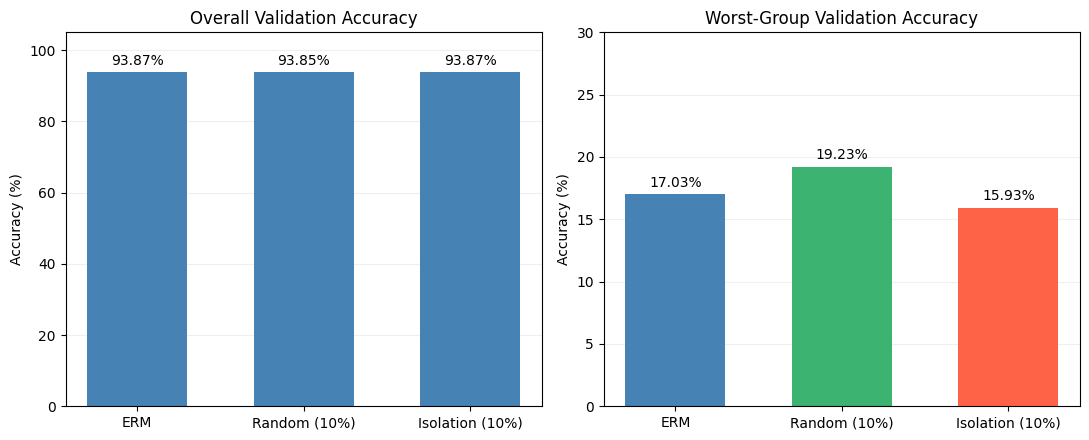

Figure saved to: results/figures/epic_10pct_performance.png
Isolation vs Random — Overall: +0.03 pp
Isolation vs Random — Worst-group: -3.30 pp


In [7]:

# ============================================================
# 3.8 Visualize 10% filtering performance
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Use measured results from Step 11.7.
plot_df = comparison.set_index("Method").loc[
    ["erm", "random", "isolation"]
]

names = ["ERM", "Random (10%)", "Isolation (10%)"]
overall = plot_df["Overall Accuracy (%)"].to_numpy()
worst = plot_df["Worst-Group Accuracy (%)"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
x = np.arange(len(names))

# Overall validation accuracy
bars1 = axes[0].bar(
    x, overall, color="steelblue", width=0.6
)
axes[0].set_title("Overall Validation Accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 105)
axes[0].bar_label(bars1, fmt="%.2f%%", padding=3)

# Worst-group validation accuracy
bars2 = axes[1].bar(
    x, worst,
    color=["steelblue", "mediumseagreen", "tomato"],
    width=0.6
)
axes[1].set_title("Worst-Group Validation Accuracy")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 30)
axes[1].bar_label(bars2, fmt="%.2f%%", padding=3)

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(names)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()

save_path = FIGURE_DIR / "epic_10pct_performance.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

# Report the differences relative to random filtering.
delta_overall = overall[2] - overall[1]
delta_worst = worst[2] - worst[1]

print(f"Figure saved to: {save_path}")
print(f"Isolation vs Random — Overall: {delta_overall:+.2f} pp")
print(f"Isolation vs Random — Worst-group: {delta_worst:+.2f} pp")


### 3.9 Multi-Seed Robustness Evaluation

Repeat ERM, random filtering, and isolation filtering using three random seeds at a 10% filtering rate. Compare mean and standard deviation of overall and worst-group validation accuracy.

In [8]:

# ============================================================
# 3.9 Multi-seed robustness comparison
# ============================================================

import copy
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

SEEDS = [42, 123, 2026]
FILTER_RATE = 0.10
EPOCHS = 20

n = len(Y)
all_indices = np.arange(n)
n_remove = round(FILTER_RATE * n)

# Fixed isolation-based selection from Step 11.6
removed_isolation = np.load(
    GRADIENT_DIR / "removed_10pct.npy"
)
keep_isolation = np.setdiff1d(
    all_indices, removed_isolation
)

val_dataset = TensorDataset(
    Xv, torch.from_numpy(Yv).long()
)
val_loader = DataLoader(
    val_dataset, batch_size=1024, shuffle=False
)

def run_experiment(indices, seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = torch.nn.Linear(512, 2).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=1e-3, weight_decay=1e-4
    )
    criterion = torch.nn.CrossEntropyLoss()

    dataset = TensorDataset(
        torch.from_numpy(np.asarray(X[indices]).copy()),
        torch.from_numpy(Y[indices].copy()).long()
    )

    loader = DataLoader(
        dataset,
        batch_size=512,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0

    for epoch in range(EPOCHS):
        model.train()

        for features, labels in loader:
            features = features.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            loss = criterion(model(features), labels)
            loss.backward()
            optimizer.step()

        model.eval()
        val_loss_sum = 0.0

        with torch.inference_mode():
            for features, labels in val_loader:
                features = features.to(device)
                labels = labels.to(device)

                loss = criterion(model(features), labels)
                val_loss_sum += loss.item() * len(labels)

        val_loss = val_loss_sum / len(Xv)

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    metrics = evaluate_model(model)

    return {
        "overall": metrics["overall"],
        "worst_group": metrics["worst_group"],
        "group_accuracies": metrics["group_accuracies"],
        "best_epoch": best_epoch,
    }

# ------------------------------------------------------------
# Run three methods across three seeds
# ------------------------------------------------------------

records = []

for seed in SEEDS:
    rng = np.random.default_rng(seed)
    removed_random = rng.choice(
        n, size=n_remove, replace=False
    )

    selections = {
        "ERM": all_indices,
        "Random": np.setdiff1d(
            all_indices, removed_random
        ),
        "Isolation": keep_isolation,
    }

    print(f"\n===== Seed {seed} =====", flush=True)

    for method, indices in selections.items():
        metrics = run_experiment(indices, seed)

        row = {
            "Seed": seed,
            "Method": method,
            "Overall Accuracy (%)": metrics["overall"],
            "Worst-Group Accuracy (%)": metrics["worst_group"],
            "Best Epoch": metrics["best_epoch"],
        }

        for g in range(4):
            row[f"G{g} Accuracy (%)"] = (
                metrics["group_accuracies"][g]
            )

        records.append(row)

        print(
            f"{method:10s} | "
            f"Overall: {metrics['overall']:.2f}% | "
            f"Worst-group: {metrics['worst_group']:.2f}% | "
            f"Best epoch: {metrics['best_epoch']}",
            flush=True
        )

# ------------------------------------------------------------
# Save results and calculate summary
# ------------------------------------------------------------

multi_seed_df = pd.DataFrame(records)

summary_df = (
    multi_seed_df.groupby("Method")
    .agg(
        Overall_Mean=("Overall Accuracy (%)", "mean"),
        Overall_Std=("Overall Accuracy (%)", "std"),
        Worst_Mean=("Worst-Group Accuracy (%)", "mean"),
        Worst_Std=("Worst-Group Accuracy (%)", "std"),
    )
    .reindex(["ERM", "Random", "Isolation"])
)

multi_seed_df.to_csv(
    METRICS_DIR / "epic_multiseed_10pct.csv",
    index=False
)

summary_df.to_csv(
    METRICS_DIR / "epic_multiseed_10pct_summary.csv"
)

print("\n" + "=" * 65)
print("Multi-Seed Robustness Summary")
print("=" * 65)

print(summary_df.round(2).to_string())

# Paired isolation vs random comparison
paired = multi_seed_df.pivot(
    index="Seed",
    columns="Method",
    values="Worst-Group Accuracy (%)"
)

differences = paired["Isolation"] - paired["Random"]

print("\nIsolation - Random (worst-group, percentage points):")
print(differences.round(2).to_string())
print(f"\nMean paired difference: {differences.mean():+.2f} pp")
print("\nMulti-seed evaluation completed!")



===== Seed 42 =====
ERM        | Overall: 93.80% | Worst-group: 15.93% | Best epoch: 18
Random     | Overall: 93.83% | Worst-group: 17.03% | Best epoch: 19
Isolation  | Overall: 93.84% | Worst-group: 14.84% | Best epoch: 20

===== Seed 123 =====
ERM        | Overall: 93.81% | Worst-group: 15.38% | Best epoch: 20
Random     | Overall: 93.84% | Worst-group: 17.58% | Best epoch: 20
Isolation  | Overall: 93.94% | Worst-group: 17.58% | Best epoch: 18

===== Seed 2026 =====
ERM        | Overall: 93.82% | Worst-group: 15.93% | Best epoch: 17
Random     | Overall: 93.79% | Worst-group: 15.38% | Best epoch: 17
Isolation  | Overall: 93.85% | Worst-group: 14.84% | Best epoch: 17

Multi-Seed Robustness Summary
           Overall_Mean  Overall_Std  Worst_Mean  Worst_Std
Method                                                     
ERM               93.81         0.01       15.75       0.32
Random            93.82         0.03       16.67       1.14
Isolation         93.88         0.05       15.75   

### 3.10 Multi-Seed Performance Analysis

Compare mean validation accuracy and variability across three seeds. Examine paired differences between isolation and random filtering to assess the consistency of robustness effects.

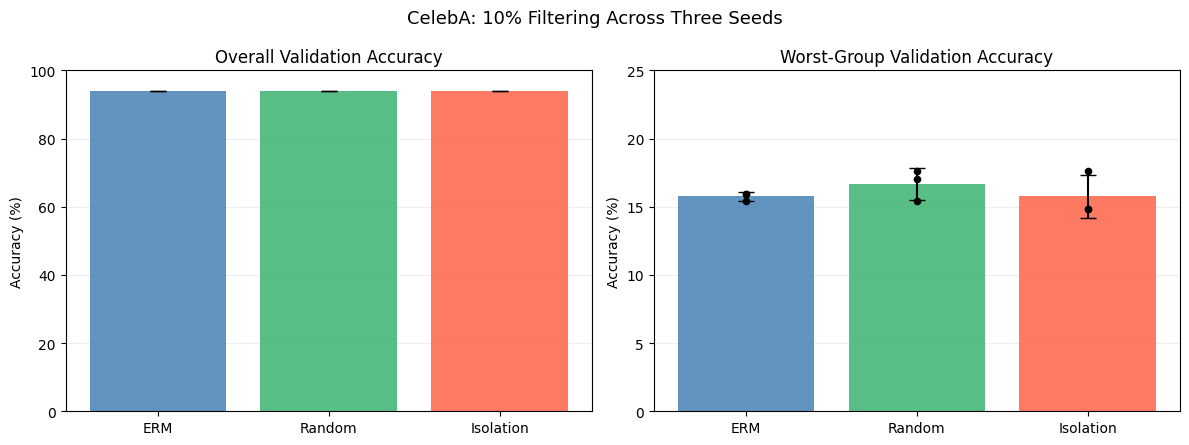

Figure saved to: results/figures/epic_multiseed_comparison.png
Mean paired difference: -0.92 pp
Error bars represent standard deviation across seeds.


In [9]:

# ============================================================
# 3.10 Multi-seed robustness visualization
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

methods = ["ERM", "Random", "Isolation"]
colors = ["steelblue", "mediumseagreen", "tomato"]
x = np.arange(len(methods))

stats = summary_df.loc[methods]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Mean overall accuracy with standard deviation
axes[0].bar(
    x,
    stats["Overall_Mean"],
    yerr=stats["Overall_Std"],
    capsize=6,
    color=colors,
    alpha=0.85
)

axes[0].set_title("Overall Validation Accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 100)

# Mean worst-group accuracy with standard deviation
axes[1].bar(
    x,
    stats["Worst_Mean"],
    yerr=stats["Worst_Std"],
    capsize=6,
    color=colors,
    alpha=0.85
)

# Show individual seed results
for i, method in enumerate(methods):
    values = multi_seed_df.loc[
        multi_seed_df["Method"] == method,
        "Worst-Group Accuracy (%)"
    ].to_numpy()

    axes[1].scatter(
        np.full(len(values), i),
        values,
        color="black",
        s=20,
        zorder=3
    )

axes[1].set_title("Worst-Group Validation Accuracy")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 25)

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(methods)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "CelebA: 10% Filtering Across Three Seeds",
    fontsize=13
)

plt.tight_layout()

save_path = FIGURE_DIR / "epic_multiseed_comparison.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {save_path}")
print(f"Mean paired difference: {differences.mean():+.2f} pp")
print("Error bars represent standard deviation across seeds.")


### 3.11 Filtering-Rate Sensitivity Analysis

Compare isolation-based and random filtering at 5%, 10%, and 20% removal rates across three seeds. Measure changes in overall and worst-group validation accuracy using matched training configurations.

In [10]:

# ============================================================
# 3.11 Filtering-rate sensitivity analysis
# ============================================================

import numpy as np
import pandas as pd

FILTER_RATES = [0.05, 0.10, 0.20]
SEEDS = [42, 123, 2026]

records = []

# Reuse existing matched 10% results.
for _, row in multi_seed_df.iterrows():
    if row["Method"] not in ["Random", "Isolation"]:
        continue

    records.append({
        "Filter Rate (%)": 10,
        "Seed": int(row["Seed"]),
        "Method": row["Method"],
        "Overall Accuracy (%)": row["Overall Accuracy (%)"],
        "Worst-Group Accuracy (%)": row["Worst-Group Accuracy (%)"],
        "Best Epoch": int(row["Best Epoch"]),
    })

# Train only the additional filtering rates.
for rate in [0.05, 0.20]:
    n_remove = round(rate * n)

    removed_isolation = np.load(
        GRADIENT_DIR / f"removed_{int(rate*100)}pct.npy"
    )

    assert len(removed_isolation) == n_remove
    assert len(np.unique(removed_isolation)) == n_remove

    keep_isolation = np.setdiff1d(
        all_indices, removed_isolation
    )

    for seed in SEEDS:
        rng = np.random.default_rng(seed)

        removed_random = rng.choice(
            n, size=n_remove, replace=False
        )

        keep_random = np.setdiff1d(
            all_indices, removed_random
        )

        selections = {
            "Random": keep_random,
            "Isolation": keep_isolation,
        }

        print(
            f"\n===== Filtering {int(rate*100)}% | "
            f"Seed {seed} =====",
            flush=True
        )

        for method, indices in selections.items():

            metrics = run_experiment(indices, seed)

            records.append({
                "Filter Rate (%)": int(rate * 100),
                "Seed": seed,
                "Method": method,
                "Overall Accuracy (%)": metrics["overall"],
                "Worst-Group Accuracy (%)": metrics["worst_group"],
                "Best Epoch": metrics["best_epoch"],
            })

            print(
                f"{method:10s} | "
                f"Overall: {metrics['overall']:.2f}% | "
                f"Worst: {metrics['worst_group']:.2f}%",
                flush=True
            )

# ------------------------------------------------------------
# Save complete experiment results
# ------------------------------------------------------------

sensitivity_df = pd.DataFrame(records).sort_values(
    ["Filter Rate (%)", "Seed", "Method"]
)

sensitivity_df.to_csv(
    METRICS_DIR / "epic_filtering_sensitivity.csv",
    index=False
)

# Aggregate results across seeds.
sensitivity_summary = (
    sensitivity_df.groupby(["Filter Rate (%)", "Method"])
    .agg(
        Overall_Mean=("Overall Accuracy (%)", "mean"),
        Overall_Std=("Overall Accuracy (%)", "std"),
        Worst_Mean=("Worst-Group Accuracy (%)", "mean"),
        Worst_Std=("Worst-Group Accuracy (%)", "std"),
    )
    .reset_index()
)

sensitivity_summary.to_csv(
    METRICS_DIR / "epic_filtering_sensitivity_summary.csv",
    index=False
)

print("\n" + "=" * 75)
print("Filtering-Rate Sensitivity — Mean ± Std")
print("=" * 75)

print(sensitivity_summary.round(2).to_string(index=False))

# ------------------------------------------------------------
# Paired differences: isolation minus random
# ------------------------------------------------------------

paired = sensitivity_df.pivot(
    index=["Filter Rate (%)", "Seed"],
    columns="Method",
    values="Worst-Group Accuracy (%)"
)

paired["Difference (pp)"] = (
    paired["Isolation"] - paired["Random"]
)

print("\nPaired Worst-Group Differences:")
print(paired["Difference (pp)"].round(2).to_string())

print("\nMean difference by filtering rate:")
print(
    paired.groupby(level=0)["Difference (pp)"]
    .mean()
    .round(2)
    .to_string()
)

print("\nFiltering-rate sensitivity analysis completed!")



===== Filtering 5% | Seed 42 =====
Random     | Overall: 93.84% | Worst: 18.68%
Isolation  | Overall: 93.86% | Worst: 14.29%

===== Filtering 5% | Seed 123 =====
Random     | Overall: 93.83% | Worst: 15.93%
Isolation  | Overall: 93.79% | Worst: 13.74%

===== Filtering 5% | Seed 2026 =====
Random     | Overall: 93.76% | Worst: 14.29%
Isolation  | Overall: 93.82% | Worst: 14.29%

===== Filtering 20% | Seed 42 =====
Random     | Overall: 93.84% | Worst: 17.58%
Isolation  | Overall: 93.77% | Worst: 14.29%

===== Filtering 20% | Seed 123 =====
Random     | Overall: 93.81% | Worst: 18.68%
Isolation  | Overall: 93.83% | Worst: 15.38%

===== Filtering 20% | Seed 2026 =====
Random     | Overall: 93.78% | Worst: 15.93%
Isolation  | Overall: 93.76% | Worst: 15.38%

Filtering-Rate Sensitivity — Mean ± Std
 Filter Rate (%)    Method  Overall_Mean  Overall_Std  Worst_Mean  Worst_Std
               5 Isolation         93.82         0.03       14.10       0.32
               5    Random         93.81

### 3.12 Filtering-Rate Sensitivity Visualization

Compare worst-group validation accuracy across filtering rates and visualize the disproportionate removal of Group 3. Error bars represent standard deviation across three training seeds.

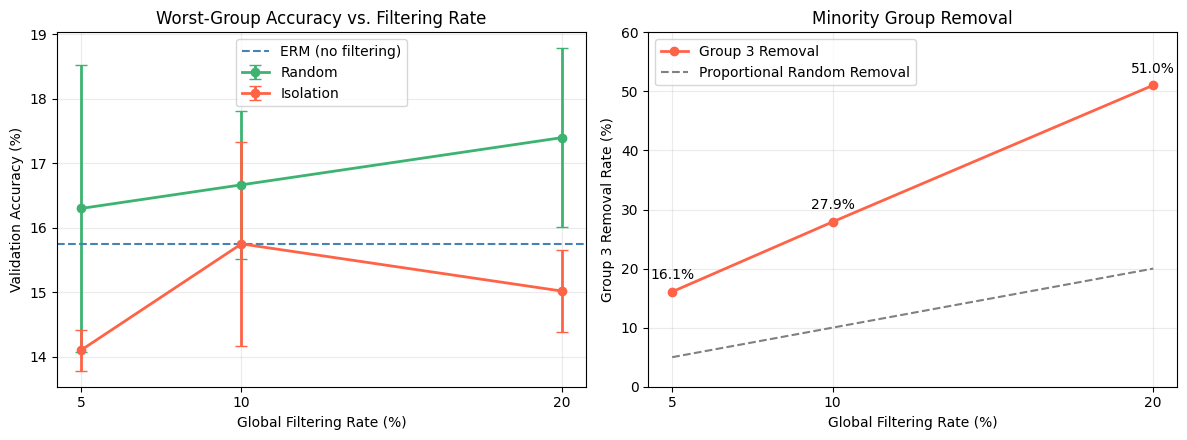

Figure saved to: results/figures/epic_filtering_sensitivity.png
Filtering-rate visualization completed!


In [11]:

# ============================================================
# 3.12 Filtering-rate sensitivity visualization
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

rates = np.array([5, 10, 20])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Worst-group accuracy across filtering rates
for method, color in [
    ("Random", "mediumseagreen"),
    ("Isolation", "tomato"),
]:
    subset = (
        sensitivity_summary[
            sensitivity_summary["Method"] == method
        ]
        .set_index("Filter Rate (%)")
        .loc[rates]
    )

    axes[0].errorbar(
        rates,
        subset["Worst_Mean"],
        yerr=subset["Worst_Std"],
        marker="o",
        linewidth=2,
        capsize=4,
        color=color,
        label=method,
    )

axes[0].axhline(
    summary_df.loc["ERM", "Worst_Mean"],
    color="steelblue",
    linestyle="--",
    label="ERM (no filtering)",
)

axes[0].set_title("Worst-Group Accuracy vs. Filtering Rate")
axes[0].set_xlabel("Global Filtering Rate (%)")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].set_xticks(rates)
axes[0].legend()
axes[0].grid(alpha=0.25)

# 2. Group 3 removal vs. global filtering rate
g3 = (
    retention_df[retention_df["Group"] == 3]
    .set_index("Filter Rate (%)")
    .loc[rates]
)

axes[1].plot(
    rates,
    g3["Removal Rate (%)"],
    marker="o",
    linewidth=2,
    color="tomato",
    label="Group 3 Removal",
)

axes[1].plot(
    rates, rates,
    linestyle="--",
    color="gray",
    label="Proportional Random Removal",
)

for rate, value in zip(rates, g3["Removal Rate (%)"]):
    axes[1].annotate(
        f"{value:.1f}%",
        (rate, value),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
    )

axes[1].set_title("Minority Group Removal")
axes[1].set_xlabel("Global Filtering Rate (%)")
axes[1].set_ylabel("Group 3 Removal Rate (%)")
axes[1].set_xticks(rates)
axes[1].set_ylim(0, 60)
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()

save_path = FIGURE_DIR / "epic_filtering_sensitivity.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {save_path}")
print("Filtering-rate visualization completed!")


### 3.13 Class-Aware Gradient Isolation

Recompute gradient isolation using reference examples from the same target class. Compare group-specific isolation and removal rates with the previous class-agnostic approach.

In [12]:

# ============================================================
# 3.13 Class-aware gradient isolation
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

REFERENCE_PER_CLASS = 512
K = 5
BATCH_SIZE = 512

rng = np.random.default_rng(SEED)
n = len(y_train)

classwise_scores = np.empty(n, dtype=np.float32)
reference_by_class = {}

# ------------------------------------------------------------
# 1. Compare gradients within each target class
# ------------------------------------------------------------

for class_id in [0, 1]:
    class_indices = np.flatnonzero(y_train == class_id)

    ref_indices = rng.choice(
        class_indices,
        size=min(REFERENCE_PER_CLASS, len(class_indices)),
        replace=False
    )

    reference_by_class[class_id] = ref_indices

    ref = torch.from_numpy(
        np.asarray(gradient_cache[ref_indices]).copy()
    ).to(device)

    ref = F.normalize(ref, p=2, dim=1, eps=1e-8)

    for start in range(0, len(class_indices), BATCH_SIZE):
        batch_indices = class_indices[start:start+BATCH_SIZE]

        batch = torch.from_numpy(
            np.asarray(gradient_cache[batch_indices]).copy()
        ).to(device)

        batch = F.normalize(batch, p=2, dim=1, eps=1e-8)

        similarities = batch @ ref.T

        # Exclude self-matches.
        match_rows, match_cols = np.where(
            batch_indices[:, None] == ref_indices[None, :]
        )

        if len(match_rows):
            similarities[
                torch.as_tensor(match_rows, device=device),
                torch.as_tensor(match_cols, device=device)
            ] = -float("inf")

        nearest = torch.topk(
            similarities, k=K, dim=1
        ).values

        classwise_scores[batch_indices] = (
            1 - nearest.mean(dim=1).cpu().numpy()
        )

    print(f"Class {class_id}: {len(class_indices):,} processed")

assert np.isfinite(classwise_scores).all()

# ------------------------------------------------------------
# 2. Compare isolation scores by group
# ------------------------------------------------------------

records = []

for g in range(4):
    mask = groups_train == g

    records.append({
        "Group": g,
        "Samples": int(mask.sum()),
        "Previous Isolation": float(
            isolation_scores[mask].mean()
        ),
        "Class-Aware Isolation": float(
            classwise_scores[mask].mean()
        )
    })

classwise_df = pd.DataFrame(records)

print("\nClass-Aware Isolation Comparison")
print(classwise_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# 3. Analyze removal at 10% global filtering
# ------------------------------------------------------------

rate = 0.10
n_remove = round(rate * n)

ranked = np.lexsort((
    np.arange(n), -classwise_scores
))

removed = ranked[:n_remove]
removed_mask = np.zeros(n, dtype=bool)
removed_mask[removed] = True

print("\n10% Class-Aware Filtering — Group Removal")

for g in range(4):
    mask = groups_train == g
    removal = 100 * np.mean(removed_mask[mask])

    print(f"Group {g}: {removal:.2f}% removed")

# ------------------------------------------------------------
# 4. Save results
# ------------------------------------------------------------

np.save(
    GRADIENT_DIR / "classwise_isolation_scores.npy",
    classwise_scores
)

np.save(
    GRADIENT_DIR / "classwise_removed_10pct.npy",
    removed
)

for class_id, indices in reference_by_class.items():
    np.save(
        GRADIENT_DIR / f"classwise_reference_{class_id}.npy",
        indices
    )

classwise_df.to_csv(
    METRICS_DIR / "epic_classwise_isolation.csv",
    index=False
)

print("\nClass-aware isolation analysis completed!")


Class 0: 138,503 processed
Class 1: 24,267 processed

Class-Aware Isolation Comparison
 Group  Samples  Previous Isolation  Class-Aware Isolation
     0    71629              0.1083                 0.1188
     1    66874              0.1239                 0.1358
     2    22880              0.1069                 0.1021
     3     1387              0.1468                 0.1396

10% Class-Aware Filtering — Group Removal
Group 0: 8.32% removed
Group 1: 14.01% removed
Group 2: 3.30% removed
Group 3: 13.91% removed

Class-aware isolation analysis completed!


### 3.14 Representative Gradient Medoids

Select representative gradients separately for each target class using a sampled greedy facility-location approximation. Assign training examples to their nearest medoid and analyze cluster sizes and minority-group representation.

In [13]:

# ============================================================
# 3.14 Class-wise representative gradient medoids
# ============================================================

import numpy as np
import pandas as pd
import torch

CANDIDATES_PER_CLASS = 256
COVERAGE_PER_CLASS = 2048
MEDOIDS_PER_CLASS = 32
ASSIGN_BATCH = 2048

rng = np.random.default_rng(SEED)

def load_grads(indices):
    return torch.from_numpy(
        np.asarray(gradient_cache[indices]).copy()
    ).to(device)

def squared_distances(a, b):
    # Pairwise squared Euclidean distances
    d = (
        (a * a).sum(1, keepdim=True)
        + (b * b).sum(1).unsqueeze(0)
        - 2 * (a @ b.T)
    )
    return d.clamp_min(0)

all_medoids = []
cluster_records = []

for class_id in [0, 1]:

    class_indices = np.flatnonzero(y_train == class_id)

    candidate_indices = rng.choice(
        class_indices,
        size=CANDIDATES_PER_CLASS,
        replace=False
    )

    coverage_indices = rng.choice(
        class_indices,
        size=COVERAGE_PER_CLASS,
        replace=False
    )

    candidates = load_grads(candidate_indices)
    coverage = load_grads(coverage_indices)

    distances = squared_distances(coverage, candidates)

    # Greedy facility-location approximation:
    # minimize sum of nearest-medoid distances.
    selected = []
    available = np.ones(CANDIDATES_PER_CLASS, dtype=bool)
    best_dist = None

    for step in range(MEDOIDS_PER_CLASS):

        if best_dist is None:
            costs = distances.sum(dim=0)
        else:
            costs = torch.minimum(
                best_dist[:, None], distances
            ).sum(dim=0)

        costs[torch.as_tensor(~available, device=device)] = float("inf")

        chosen = int(torch.argmin(costs).item())
        selected.append(chosen)
        available[chosen] = False

        if best_dist is None:
            best_dist = distances[:, chosen].clone()
        else:
            best_dist = torch.minimum(
                best_dist, distances[:, chosen]
            )

    medoid_indices = candidate_indices[selected]
    all_medoids.extend(medoid_indices.tolist())

    # Assign every example in this class to its nearest medoid.
    medoid_grads = load_grads(medoid_indices)
    cluster_sizes = np.zeros(MEDOIDS_PER_CLASS, dtype=np.int64)
    group_counts = np.zeros((MEDOIDS_PER_CLASS, 4), dtype=np.int64)

    for start in range(0, len(class_indices), ASSIGN_BATCH):
        ids = class_indices[start:start + ASSIGN_BATCH]

        d = squared_distances(load_grads(ids), medoid_grads)
        assignments = d.argmin(dim=1).cpu().numpy()

        cluster_sizes += np.bincount(
            assignments, minlength=MEDOIDS_PER_CLASS
        )

        for g in range(4):
            group_counts[:, g] += np.bincount(
                assignments[groups_train[ids] == g],
                minlength=MEDOIDS_PER_CLASS
            )

    for j, medoid_id in enumerate(medoid_indices):
        record = {
            "Class": class_id,
            "Medoid Index": int(medoid_id),
            "Cluster Size": int(cluster_sizes[j]),
        }

        for g in range(4):
            record[f"G{g} Count"] = int(group_counts[j, g])

        cluster_records.append(record)

    print(
        f"Class {class_id}: "
        f"{MEDOIDS_PER_CLASS} medoids, "
        f"{(cluster_sizes == 1).sum()} singleton clusters, "
        f"smallest cluster {cluster_sizes.min():,}"
    )

# ------------------------------------------------------------
# Save pilot results
# ------------------------------------------------------------

medoid_df = pd.DataFrame(cluster_records)

medoid_df.to_csv(
    METRICS_DIR / "epic_medoid_pilot.csv",
    index=False
)

np.save(
    GRADIENT_DIR / "epic_pilot_medoids.npy",
    np.array(all_medoids)
)

print("\nCluster size summary:")
print(
    medoid_df.groupby("Class")["Cluster Size"]
    .describe()
    .round(1)
    .to_string()
)

print("\nMedoid pilot completed successfully!")


Class 0: 32 medoids, 0 singleton clusters, smallest cluster 76
Class 1: 32 medoids, 0 singleton clusters, smallest cluster 25

Cluster size summary:
       count    mean      std   min    25%    50%     75%      max
Class                                                             
0       32.0  4328.2  10478.2  76.0  555.2  974.0  2522.2  53667.0
1       32.0   758.3   1113.7  25.0  244.8  302.5   654.8   4825.0

Medoid pilot completed successfully!


### 3.15 Medoid Coverage Analysis

Analyze group representation among selected medoids and the distribution of minority examples across clusters. Identify whether rare-group examples are represented by distinct gradient centers.

Medoid Representation
 Group  Train Share (%)  Medoid Share (%)  Selected Medoids
     0            44.01             31.25                20
     1            41.08             18.75                12
     2            14.06             45.31                29
     3             0.85              4.69                 3

Group 3 Cluster Coverage
Clusters containing G3 examples: 32 / 32
G3 examples assigned to G3 medoids: 402

Top 10 clusters by G3 share:
 Medoid Group  Cluster Size  G3 Count  G3 Share (%)
            3           116       110         94.83
            3           254       147         57.87
            3           270       145         53.70
            2           235        70         29.79
            2           186        55         29.57
            2           453       116         25.61
            2            65        16         24.62
            2            94        20         21.28
            2           445        92         20.67
            2        

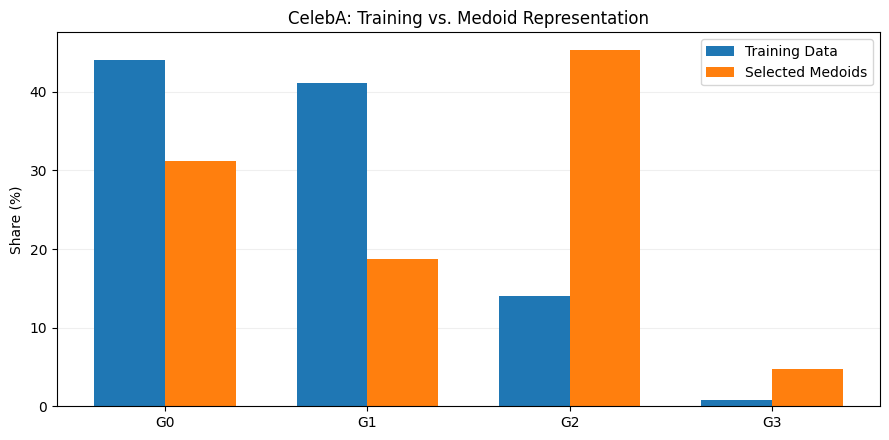


Figure saved to: results/figures/epic_medoid_coverage.png
Medoid coverage analysis completed!


In [14]:

# ============================================================
# 3.15 Medoid coverage and minority representation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add the group membership of each selected medoid.
medoid_df["Medoid Group"] = groups_train[
    medoid_df["Medoid Index"].to_numpy(dtype=int)
]

# ------------------------------------------------------------
# 1. Compare medoid representation with training distribution
# ------------------------------------------------------------

records = []

for g in range(4):
    total = int((groups_train == g).sum())
    selected = int((medoid_df["Medoid Group"] == g).sum())

    records.append({
        "Group": g,
        "Train Share (%)": 100 * total / len(groups_train),
        "Medoid Share (%)": 100 * selected / len(medoid_df),
        "Selected Medoids": selected,
    })

coverage_df = pd.DataFrame(records)

print("Medoid Representation")
print("=" * 60)
print(coverage_df.round(2).to_string(index=False))

# ------------------------------------------------------------
# 2. Examine Group 3 cluster coverage
# ------------------------------------------------------------

blond_clusters = medoid_df[
    medoid_df["Class"] == 1
].copy()

blond_clusters["G3 Share (%)"] = (
    100 * blond_clusters["G3 Count"]
    / blond_clusters["Cluster Size"]
)

print("\nGroup 3 Cluster Coverage")
print("=" * 60)

print(
    f"Clusters containing G3 examples: "
    f"{(blond_clusters['G3 Count'] > 0).sum()} / "
    f"{len(blond_clusters)}"
)

print(
    f"G3 examples assigned to G3 medoids: "
    f"{blond_clusters.loc[blond_clusters['Medoid Group'] == 3, 'G3 Count'].sum():,}"
)

print("\nTop 10 clusters by G3 share:")
print(
    blond_clusters.nlargest(10, "G3 Share (%)")[
        ["Medoid Group", "Cluster Size",
         "G3 Count", "G3 Share (%)"]
    ].round(2).to_string(index=False)
)

# ------------------------------------------------------------
# 3. Visualize medoid representation
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 4.5))

x = np.arange(4)
width = 0.35

ax.bar(
    x - width / 2,
    coverage_df["Train Share (%)"],
    width,
    label="Training Data"
)

ax.bar(
    x + width / 2,
    coverage_df["Medoid Share (%)"],
    width,
    label="Selected Medoids"
)

ax.set_xticks(x)
ax.set_xticklabels(["G0", "G1", "G2", "G3"])
ax.set_ylabel("Share (%)")
ax.set_title("CelebA: Training vs. Medoid Representation")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

save_path = FIGURE_DIR / "epic_medoid_coverage.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

coverage_df.to_csv(
    METRICS_DIR / "epic_medoid_coverage.csv",
    index=False
)

print(f"\nFigure saved to: {save_path}")
print("Medoid coverage analysis completed!")


### 3.16 Higher-Resolution Medoid Selection

Increase the number of gradient medoids to analyze cluster-size distributions and singleton clusters. Evaluate whether finer representative-center selection identifies isolated training examples.

In [15]:

# ============================================================
# 3.16 Higher-resolution gradient medoid selection
# ============================================================

import numpy as np
import pandas as pd
import torch

CANDIDATES = 1024
COVERAGE = 4096
MEDOIDS = 128
BATCH_SIZE = 2048

rng = np.random.default_rng(SEED + 1)
records = []
selected_indices = []

for class_id in [0, 1]:

    class_indices = np.flatnonzero(y_train == class_id)

    candidate_ids = rng.choice(
        class_indices, CANDIDATES, replace=False
    )

    coverage_ids = rng.choice(
        class_indices, COVERAGE, replace=False
    )

    candidates = load_grads(candidate_ids)
    coverage = load_grads(coverage_ids)

    distances = squared_distances(coverage, candidates)

    selected = []
    available = torch.ones(
        CANDIDATES, dtype=torch.bool, device=device
    )

    best_dist = torch.full(
        (COVERAGE,), float("inf"), device=device
    )

    # Greedy facility-location approximation
    for _ in range(MEDOIDS):

        costs = torch.minimum(
            best_dist[:, None], distances
        ).sum(dim=0)

        costs[~available] = float("inf")

        chosen = int(torch.argmin(costs).item())

        selected.append(chosen)
        available[chosen] = False

        best_dist = torch.minimum(
            best_dist, distances[:, chosen]
        )

    medoid_ids = candidate_ids[selected]
    selected_indices.extend(medoid_ids.tolist())

    medoid_grads = load_grads(medoid_ids)

    cluster_sizes = np.zeros(MEDOIDS, dtype=np.int64)
    group_counts = np.zeros((MEDOIDS, 4), dtype=np.int64)

    # Assign all examples to nearest class-specific medoid
    for start in range(0, len(class_indices), BATCH_SIZE):
        ids = class_indices[start:start + BATCH_SIZE]

        d = squared_distances(
            load_grads(ids), medoid_grads
        )

        assignments = d.argmin(dim=1).cpu().numpy()

        cluster_sizes += np.bincount(
            assignments, minlength=MEDOIDS
        )

        for g in range(4):
            mask = groups_train[ids] == g
            group_counts[:, g] += np.bincount(
                assignments[mask], minlength=MEDOIDS
            )

    for j, idx in enumerate(medoid_ids):
        record = {
            "Class": class_id,
            "Medoid Index": int(idx),
            "Medoid Group": int(groups_train[idx]),
            "Cluster Size": int(cluster_sizes[j]),
        }

        for g in range(4):
            record[f"G{g} Count"] = int(group_counts[j, g])

        records.append(record)

    print(f"\nClass {class_id}")
    print(f"Selected medoids: {MEDOIDS}")
    print(f"Smallest cluster: {cluster_sizes.min():,}")
    print(f"Median cluster: {np.median(cluster_sizes):.0f}")
    print(f"Singleton clusters: {(cluster_sizes == 1).sum()}")
    print(f"Clusters <= 5: {(cluster_sizes <= 5).sum()}")
    print(f"Clusters <= 10: {(cluster_sizes <= 10).sum()}")

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

highres_df = pd.DataFrame(records)

highres_df.to_csv(
    METRICS_DIR / "epic_highres_medoids.csv",
    index=False
)

np.save(
    GRADIENT_DIR / "epic_highres_medoids.npy",
    np.array(selected_indices)
)

print("\n" + "=" * 55)
print("Higher-Resolution Medoid Summary")
print("=" * 55)

print(
    highres_df.groupby("Class")["Cluster Size"]
    .describe().round(1).to_string()
)

print("\nMedoid distribution by group:")
print(
    highres_df["Medoid Group"]
    .value_counts().sort_index().to_string()
)

print("\nHigher-resolution analysis completed!")



Class 0
Selected medoids: 128
Smallest cluster: 12
Median cluster: 157
Singleton clusters: 0
Clusters <= 5: 0
Clusters <= 10: 0

Class 1
Selected medoids: 128
Smallest cluster: 1
Median cluster: 59
Singleton clusters: 1
Clusters <= 5: 2
Clusters <= 10: 13

Higher-Resolution Medoid Summary
       count    mean     std   min   25%    50%    75%      max
Class                                                          
0      128.0  1082.1  5455.2  12.0  80.5  157.0  387.5  57923.0
1      128.0   189.6   563.0   1.0  26.8   59.0  115.2   4789.0

Medoid distribution by group:
Medoid Group
0    105
1     23
2    109
3     19

Higher-resolution analysis completed!


### 3.17 Singleton and Small-Cluster Analysis

Inspect singleton medoids and clusters containing at most 10 examples. Analyze their group membership before applying EPIC-style removal.

In [16]:

# ============================================================
# 3.17 Analyze singleton and small gradient clusters
# ============================================================

import numpy as np
import pandas as pd

# 1. Singleton clusters
singletons = highres_df[
    highres_df["Cluster Size"] == 1
].copy()

print("Singleton Medoids")
print("=" * 65)

print(singletons.to_string(index=False))

# 2. Small clusters
small_clusters = highres_df[
    highres_df["Cluster Size"] <= 10
].copy()

print("\nSmall Clusters (size <= 10)")
print("=" * 65)

print(
    small_clusters[
        ["Class", "Medoid Group", "Cluster Size",
         "G0 Count", "G1 Count", "G2 Count", "G3 Count"]
    ].sort_values("Cluster Size").to_string(index=False)
)

# 3. Group distribution of small-cluster assignments
group_columns = [f"G{g} Count" for g in range(4)]

small_group_counts = (
    small_clusters[group_columns].sum()
)

print("\nExamples Assigned to Small Clusters")
print("=" * 65)

for g in range(4):
    print(f"Group {g}: {int(small_group_counts[f'G{g} Count']):,}")

# 4. Save analysis
singletons.to_csv(
    METRICS_DIR / "epic_singleton_clusters.csv",
    index=False
)

small_clusters.to_csv(
    METRICS_DIR / "epic_small_clusters.csv",
    index=False
)

print("\nSingleton and small-cluster analysis completed!")


Singleton Medoids
 Class  Medoid Index  Medoid Group  Cluster Size  G0 Count  G1 Count  G2 Count  G3 Count
     1        119681             2             1         0         0         1         0

Small Clusters (size <= 10)
 Class  Medoid Group  Cluster Size  G0 Count  G1 Count  G2 Count  G3 Count
     1             2             1         0         0         1         0
     1             2             4         0         0         4         0
     1             2             6         0         0         6         0
     1             2             6         0         0         6         0
     1             2             6         0         0         5         1
     1             2             6         0         0         6         0
     1             2             6         0         0         6         0
     1             2             7         0         0         5         2
     1             2             8         0         0         7         1
     1             2     

### 3.18 Small-Cluster Sensitivity

Analyze group-specific small-cluster membership rates across cluster-size thresholds. Compare minority representation without removing additional training examples.

Small-Cluster Membership by Threshold
Group          0      1      2       3
Threshold                             
1          0.000  0.000  0.004   0.000
5          0.000  0.000  0.022   0.000
10         0.000  0.000  0.328   0.937
20         0.082  0.003  0.940   4.326
50         0.496  0.138  5.044  19.539


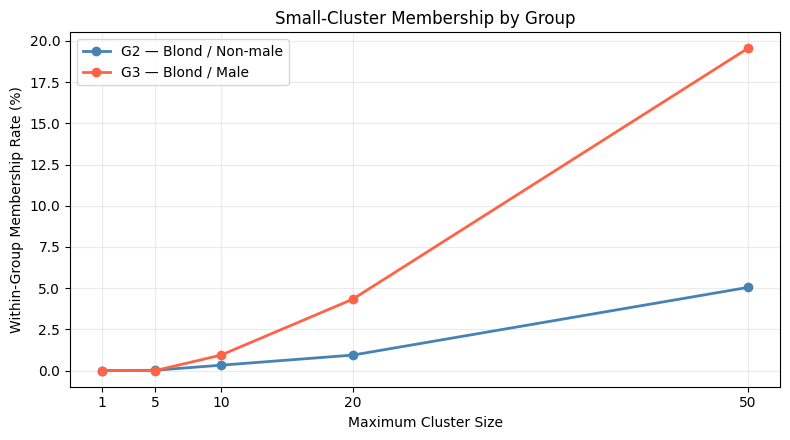


Figure saved to: results/figures/epic_cluster_threshold_sensitivity.png
Cluster sensitivity analysis completed!


In [17]:

# ============================================================
# 3.18 Small-cluster sensitivity analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

THRESHOLDS = [1, 5, 10, 20, 50]
group_sizes = np.bincount(groups_train, minlength=4)
records = []

for threshold in THRESHOLDS:
    small = highres_df[
        highres_df["Cluster Size"] <= threshold
    ]

    for g in range(4):
        count = int(small[f"G{g} Count"].sum())

        records.append({
            "Threshold": threshold,
            "Group": g,
            "Examples": count,
            "Membership Rate (%)": (
                100 * count / group_sizes[g]
            )
        })

threshold_df = pd.DataFrame(records)

print("Small-Cluster Membership by Threshold")
print("=" * 65)

table = threshold_df.pivot(
    index="Threshold",
    columns="Group",
    values="Membership Rate (%)"
)

print(table.round(3).to_string())

# Compare the two blond groups.
fig, ax = plt.subplots(figsize=(8, 4.5))

for g, label, color in [
    (2, "G2 — Blond / Non-male", "steelblue"),
    (3, "G3 — Blond / Male", "tomato"),
]:
    subset = threshold_df[
        threshold_df["Group"] == g
    ]

    ax.plot(
        subset["Threshold"],
        subset["Membership Rate (%)"],
        marker="o",
        linewidth=2,
        color=color,
        label=label
    )

ax.set_title("Small-Cluster Membership by Group")
ax.set_xlabel("Maximum Cluster Size")
ax.set_ylabel("Within-Group Membership Rate (%)")
ax.set_xticks(THRESHOLDS)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

save_path = FIGURE_DIR / "epic_cluster_threshold_sensitivity.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

threshold_df.to_csv(
    METRICS_DIR / "epic_cluster_threshold_sensitivity.csv",
    index=False
)

print(f"\nFigure saved to: {save_path}")
print("Cluster sensitivity analysis completed!")


### 3.19 Medoid Selection Stability

Repeat representative-medoid selection across five seeds. Measure variation in singleton counts and group-specific small-cluster membership rates.

Seed 43: 1 singletons | G2 @50: 5.04% | G3 @50: 19.54%
Seed 44: 0 singletons | G2 @50: 4.97% | G3 @50: 26.17%
Seed 45: 1 singletons | G2 @50: 4.72% | G3 @50: 18.24%
Seed 46: 1 singletons | G2 @50: 4.79% | G3 @50: 27.33%
Seed 47: 2 singletons | G2 @50: 4.95% | G3 @50: 25.38%

Mean ± Std Membership Rates
 Threshold  Group   mean   std
        10      2  0.224 0.075
        10      3  1.255 0.516
        20      2  0.805 0.077
        20      3  3.937 1.122
        50      2  4.893 0.137
        50      3 23.331 4.138

Singleton counts:
 Seed  Singletons
   43           1
   44           0
   45           1
   46           1
   47           2


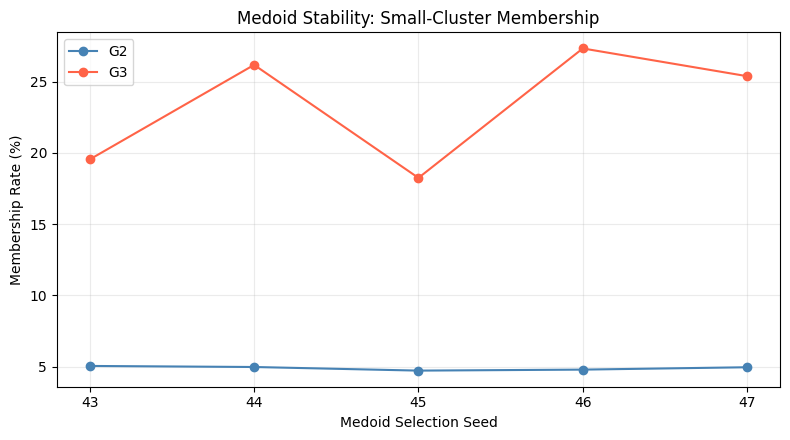


Medoid stability analysis completed!


In [18]:

# ============================================================
# 3.19 Medoid stability across five seeds
# ============================================================

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

SELECTION_SEEDS = [43, 44, 45, 46, 47]
THRESHOLDS = [10, 20, 50]

records = []
singleton_records = []

group_sizes = np.bincount(groups_train, minlength=4)

for seed in SELECTION_SEEDS:
    rng = np.random.default_rng(seed)

    group_small_counts = {
        t: np.zeros(4, dtype=np.int64)
        for t in THRESHOLDS
    }

    singleton_count = 0

    for class_id in [0, 1]:
        class_indices = np.flatnonzero(y_train == class_id)

        candidate_ids = rng.choice(
            class_indices, 1024, replace=False
        )
        coverage_ids = rng.choice(
            class_indices, 4096, replace=False
        )

        candidates = load_grads(candidate_ids)
        coverage = load_grads(coverage_ids)

        distances = squared_distances(
            coverage, candidates
        )

        selected = []
        available = torch.ones(
            1024, dtype=torch.bool, device=device
        )
        best_dist = torch.full(
            (4096,), float("inf"), device=device
        )

        # Greedy representative-medoid selection
        for _ in range(128):
            costs = torch.minimum(
                best_dist[:, None], distances
            ).sum(dim=0)

            costs[~available] = float("inf")
            chosen = int(torch.argmin(costs).item())

            selected.append(chosen)
            available[chosen] = False

            best_dist = torch.minimum(
                best_dist, distances[:, chosen]
            )

        medoid_grads = load_grads(
            candidate_ids[selected]
        )

        # Assign each training example to its nearest medoid.
        assignments_all = np.empty(
            len(class_indices), dtype=np.int32
        )

        for start in range(0, len(class_indices), 2048):
            end = min(start + 2048, len(class_indices))

            d = squared_distances(
                load_grads(class_indices[start:end]),
                medoid_grads
            )

            assignments_all[start:end] = (
                d.argmin(dim=1).cpu().numpy()
            )

        sizes = np.bincount(
            assignments_all, minlength=128
        )

        singleton_count += int((sizes == 1).sum())

        example_cluster_sizes = sizes[assignments_all]
        example_groups = groups_train[class_indices]

        for threshold in THRESHOLDS:
            small = example_cluster_sizes <= threshold

            group_small_counts[threshold] += np.bincount(
                example_groups[small], minlength=4
            )

    singleton_records.append({
        "Seed": seed,
        "Singletons": singleton_count
    })

    for threshold in THRESHOLDS:
        for g in range(4):
            records.append({
                "Seed": seed,
                "Threshold": threshold,
                "Group": g,
                "Membership Rate (%)": (
                    100 * group_small_counts[threshold][g]
                    / group_sizes[g]
                )
            })

    print(
        f"Seed {seed}: {singleton_count} singletons | "
        f"G2 @50: "
        f"{100*group_small_counts[50][2]/group_sizes[2]:.2f}% | "
        f"G3 @50: "
        f"{100*group_small_counts[50][3]/group_sizes[3]:.2f}%",
        flush=True
    )

# ------------------------------------------------------------
# Summarize results
# ------------------------------------------------------------

stability_df = pd.DataFrame(records)
singleton_df = pd.DataFrame(singleton_records)

summary = (
    stability_df.groupby(["Threshold", "Group"])
    ["Membership Rate (%)"]
    .agg(["mean", "std"])
    .reset_index()
)

print("\nMean ± Std Membership Rates")
print(
    summary[summary["Group"].isin([2, 3])]
    .round(3).to_string(index=False)
)

print("\nSingleton counts:")
print(singleton_df.to_string(index=False))

# ------------------------------------------------------------
# Plot G2 and G3 at threshold 50
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4.5))

subset = stability_df[
    (stability_df["Threshold"] == 50)
    & (stability_df["Group"].isin([2, 3]))
]

for g, color in [(2, "steelblue"), (3, "tomato")]:
    data = subset[subset["Group"] == g]

    ax.plot(
        data["Seed"],
        data["Membership Rate (%)"],
        marker="o",
        color=color,
        label=f"G{g}"
    )

ax.set_title("Medoid Stability: Small-Cluster Membership")
ax.set_xlabel("Medoid Selection Seed")
ax.set_ylabel("Membership Rate (%)")
ax.set_xticks(SELECTION_SEEDS)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "epic_medoid_stability.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

stability_df.to_csv(
    METRICS_DIR / "epic_medoid_stability.csv",
    index=False
)

summary.to_csv(
    METRICS_DIR / "epic_medoid_stability_summary.csv",
    index=False
)

singleton_df.to_csv(
    METRICS_DIR / "epic_medoid_singleton_counts.csv",
    index=False
)

print("\nMedoid stability analysis completed!")
